# E-commerce Data Analysis Project

In this project, we will:
1. Generate mock e-commerce datasets (Customers, Products, and Orders).
2. Perform exploratory data analysis (EDA).
3. Analyze sales trends, customer behavior, and product performance.

In [1]:
import pandas as pd
import numpy as np
from datetime import datetime, timedelta

# Set random seed for reproducibility
np.random.seed(42)

# 1. Generate Customers Data
num_customers = 100
customers_data = {
    'customer_id': [f'C_{1000 + i}' for i in range(num_customers)],
    'age': np.random.randint(18, 70, size=num_customers),
    'gender': np.random.choice(['M', 'F', 'O'], size=num_customers, p=[0.45, 0.45, 0.10]),
    'signup_date': [datetime(2023, 1, 1) + timedelta(days=int(np.random.randint(0, 365))) for _ in range(num_customers)]
}
df_customers = pd.DataFrame(customers_data)

# 2. Generate Products Data
products = {
    'P_001': ('Laptop', 'Electronics', 999.99),
    'P_002': ('Smartphone', 'Electronics', 599.99),
    'P_003': ('Headphones', 'Electronics', 99.99),
    'P_004': ('Running Shoes', 'Apparel', 79.99),
    'P_005': ('T-Shirt', 'Apparel', 19.99),
    'P_006': ('Coffee Maker', 'Home & Kitchen', 49.99),
    'P_007': ('Blender', 'Home & Kitchen', 39.99),
    'P_008': ('Novel Book', 'Books', 14.99),
    'P_009': ('Desk Chair', 'Office', 149.99),
    'P_010': ('Backpack', 'Travel', 45.00)
}

df_products = pd.DataFrame([
    {'product_id': pid, 'product_name': name, 'category': cat, 'price': price}
    for pid, (name, cat, price) in products.items()
])

# 3. Generate Orders Data
num_orders = 500
order_ids = [f'O_{10000 + i}' for i in range(num_orders)]
customer_ids = np.random.choice(df_customers['customer_id'], size=num_orders)
product_ids = np.random.choice(df_products['product_id'], size=num_orders, p=[0.05, 0.10, 0.15, 0.15, 0.20, 0.10, 0.08, 0.07, 0.05, 0.05])
quantities = np.random.choice([1, 2, 3], size=num_orders, p=[0.7, 0.2, 0.1])
order_dates = [datetime(2024, 1, 1) + timedelta(days=int(np.random.randint(0, 180))) for _ in range(num_orders)]

df_orders = pd.DataFrame({
    'order_id': order_ids,
    'customer_id': customer_ids,
    'product_id': product_ids,
    'quantity': quantities,
    'order_date': order_dates
})

# Merge prices to calculate total order values
df_orders = df_orders.merge(df_products[['product_id', 'price']], on='product_id', how='left')
df_orders['total_value'] = df_orders['quantity'] * df_orders['price']
df_orders.drop(columns=['price'], inplace=True)

print("Datasets successfully generated!")

Datasets successfully generated!


In [2]:
print("=== Customers Preview ===")
display(df_customers.head())

print("\n=== Products Preview ===")
display(df_products)

print("\n=== Orders Preview ===")
display(df_orders.head())

=== Customers Preview ===


,customer_id,age,gender,signup_date
0,C_1000,56,M,2023-12-15
1,C_1001,69,M,2023-09-16
2,C_1002,46,M,2023-05-28
3,C_1003,32,M,2023-09-09
4,C_1004,60,M,2023-12-12



=== Products Preview ===


,product_id,product_name,category,price
0,P_001,Laptop,Electronics,999.99
1,P_002,Smartphone,Electronics,599.99
2,P_003,Headphones,Electronics,99.99
3,P_004,Running Shoes,Apparel,79.99
4,P_005,T-Shirt,Apparel,19.99
5,P_006,Coffee Maker,Home & Kitchen,49.99
6,P_007,Blender,Home & Kitchen,39.99
7,P_008,Novel Book,Books,14.99
8,P_009,Desk Chair,Office,149.99
9,P_010,Backpack,Travel,45.00



=== Orders Preview ===


,order_id,customer_id,product_id,quantity,order_date,total_value
0,O_10000,C_1023,P_004,1,2024-03-09,79.99
1,O_10001,C_1092,P_005,1,2024-06-23,19.99
2,O_10002,C_1045,P_007,1,2024-02-18,39.99
3,O_10003,C_1052,P_004,1,2024-04-17,79.99
4,O_10004,C_1094,P_005,1,2024-06-09,19.99


## Phase 2: Exploratory Data Analysis (EDA)

Let's start by calculating fundamental business metrics and analyzing sales performance across categories.

In [3]:
# 1. Check for missing values and overall data structure
print("=== Missing Values Summary ===")
for name, df in [('Customers', df_customers), ('Products', df_products), ('Orders', df_orders)]:
    print(f"{name} missing values:")
    print(df.isnull().sum(), "\n")

=== Missing Values Summary ===
Customers missing values:
customer_id    0
age            0
gender         0
signup_date    0
dtype: int64 

Products missing values:
product_id      0
product_name    0
category        0
price           0
dtype: int64 

Orders missing values:
order_id       0
customer_id    0
product_id     0
quantity       0
order_date     0
total_value    0
dtype: int64 



In [4]:
# 2. Calculate Key Performance Indicators (KPIs)
total_revenue = df_orders['total_value'].sum()
total_orders = df_orders['order_id'].nunique()
unique_customers = df_orders['customer_id'].nunique()
average_order_value = total_revenue / total_orders

print("=== Overall KPIs ===")
print(f"Total Revenue: ${total_revenue:,.2f}")
print(f"Total Orders Placed: {total_orders}")
print(f"Unique Customers Buying: {unique_customers}")
print(f"Average Order Value (AOV): ${average_order_value:,.2f}")

=== Overall KPIs ===
Total Revenue: $117,233.18
Total Orders Placed: 500
Unique Customers Buying: 99
Average Order Value (AOV): $234.47


In [5]:
# 3. Group by category to find top-performing categories
df_merged = df_orders.merge(df_products, on='product_id', how='left')

category_summary = df_merged.groupby('category').agg(
    total_sales=('total_value', 'sum'),
    quantity_sold=('quantity', 'sum'),
    number_of_orders=('order_id', 'count')
).sort_values(by='total_sales', ascending=False).reset_index()

print("=== Category Performance ===")
display(category_summary)

=== Category Performance ===


,category,total_sales,quantity_sold,number_of_orders
0,Electronics,93397.56,244,167
1,Apparel,10997.56,244,175
2,Office,6599.56,44,30
3,Home & Kitchen,4648.99,101,78
4,Travel,855.00,19,15
5,Books,734.51,49,35


## Phase 3: Data Visualization

Let's visualize our metrics to spot monthly sales trends and category performance clearly.

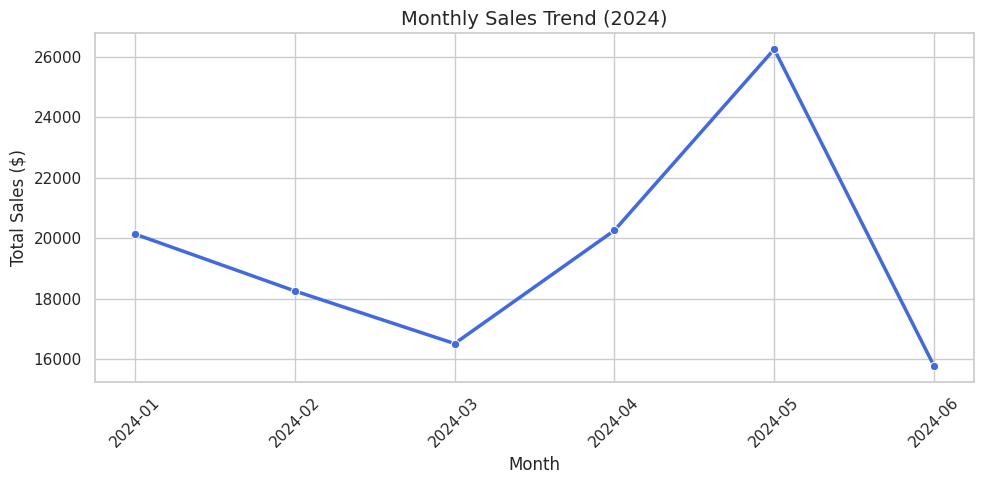

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configure styling
sns.set_theme(style="whitegrid")

# 1. Monthly Sales Trend
df_orders['order_month'] = df_orders['order_date'].dt.to_period('M')
monthly_sales = df_orders.groupby('order_month')['total_value'].sum().reset_index()
monthly_sales['order_month'] = monthly_sales['order_month'].astype(str)

plt.figure(figsize=(10, 5))
sns.lineplot(data=monthly_sales, x='order_month', y='total_value', marker='o', color='royalblue', linewidth=2.5)
plt.title('Monthly Sales Trend (2024)', fontsize=14)
plt.xlabel('Month', fontsize=12)
plt.ylabel('Total Sales ($)', fontsize=12)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

/tmp/ipykernel_821/257530011.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=category_summary, x='total_sales', y='category', palette='viridis')


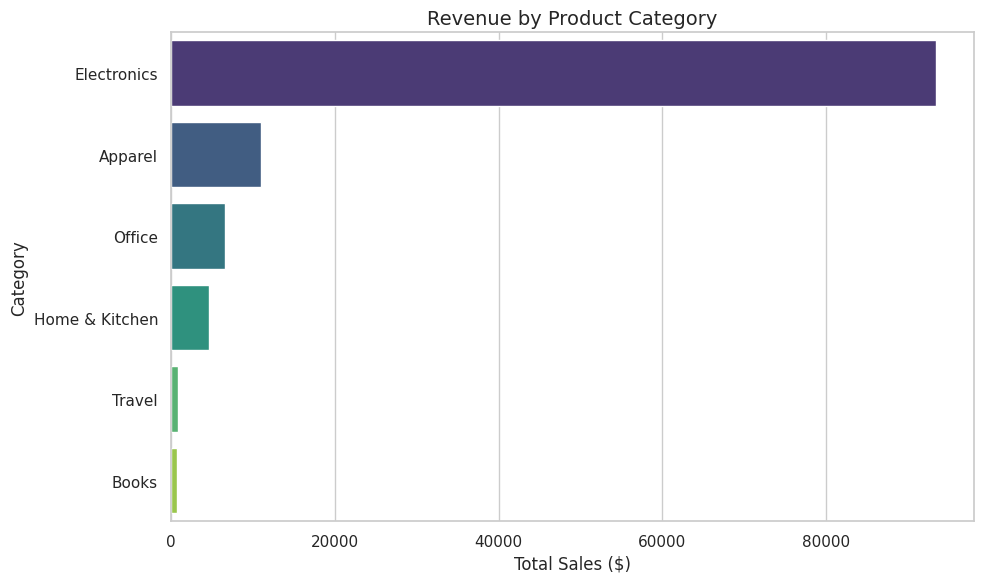

In [7]:
# 2. Revenue Distribution by Category
plt.figure(figsize=(10, 6))
sns.barplot(data=category_summary, x='total_sales', y='category', palette='viridis')
plt.title('Revenue by Product Category', fontsize=14)
plt.xlabel('Total Sales ($)', fontsize=12)
plt.ylabel('Category', fontsize=12)
plt.tight_layout()
plt.show()

## Phase 3: Data Visualization

Let's visualize our metrics to spot monthly sales trends and category performance clearly.

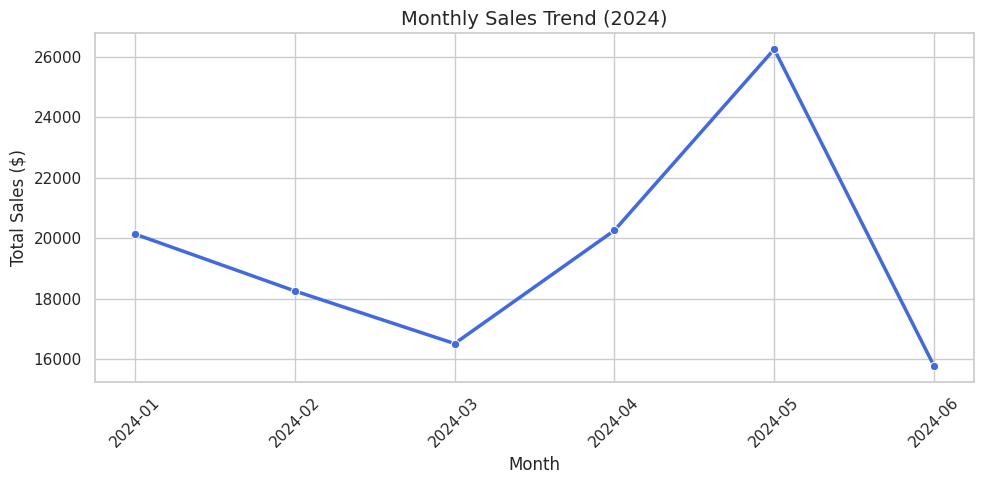

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configure styling
sns.set_theme(style="whitegrid")

# 1. Monthly Sales Trend
df_orders['order_month'] = df_orders['order_date'].dt.to_period('M')
monthly_sales = df_orders.groupby('order_month')['total_value'].sum().reset_index()
monthly_sales['order_month'] = monthly_sales['order_month'].astype(str)

plt.figure(figsize=(10, 5))
sns.lineplot(data=monthly_sales, x='order_month', y='total_value', marker='o', color='royalblue', linewidth=2.5)
plt.title('Monthly Sales Trend (2024)', fontsize=14)
plt.xlabel('Month', fontsize=12)
plt.ylabel('Total Sales ($)', fontsize=12)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

/tmp/ipykernel_821/257530011.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=category_summary, x='total_sales', y='category', palette='viridis')


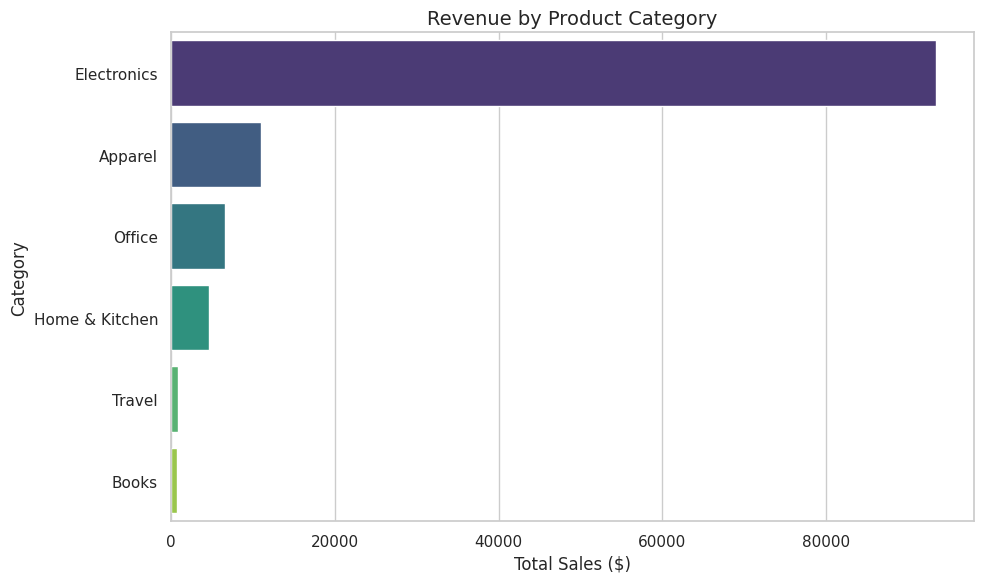

In [9]:
# 2. Revenue Distribution by Category
plt.figure(figsize=(10, 6))
sns.barplot(data=category_summary, x='total_sales', y='category', palette='viridis')
plt.title('Revenue by Product Category', fontsize=14)
plt.xlabel('Total Sales ($)', fontsize=12)
plt.ylabel('Category', fontsize=12)
plt.tight_layout()
plt.show()

## Phase 3: Data Visualization

Let's visualize the data to extract trends and insights.

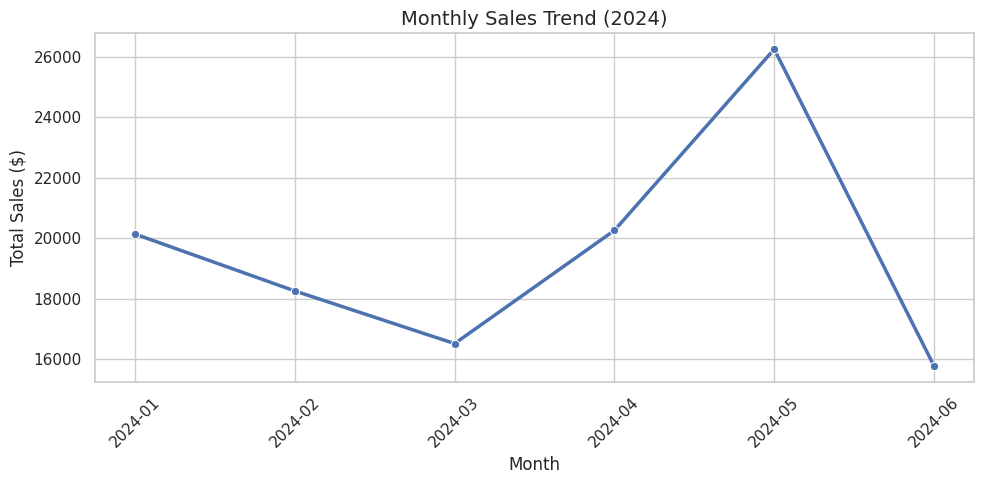

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set plotting style
sns.set_theme(style="whitegrid")

# 1. Monthly Sales Trend Analysis
df_orders['order_month'] = df_orders['order_date'].dt.to_period('M')
monthly_sales = df_orders.groupby('order_month')['total_value'].sum().reset_index()
monthly_sales['order_month'] = monthly_sales['order_month'].astype(str)

plt.figure(figsize=(10, 5))
sns.lineplot(data=monthly_sales, x='order_month', y='total_value', marker='o', color='b', linewidth=2.5)
plt.title('Monthly Sales Trend (2024)', fontsize=14)
plt.xlabel('Month', fontsize=12)
plt.ylabel('Total Sales ($)', fontsize=12)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

/tmp/ipykernel_821/257530011.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=category_summary, x='total_sales', y='category', palette='viridis')


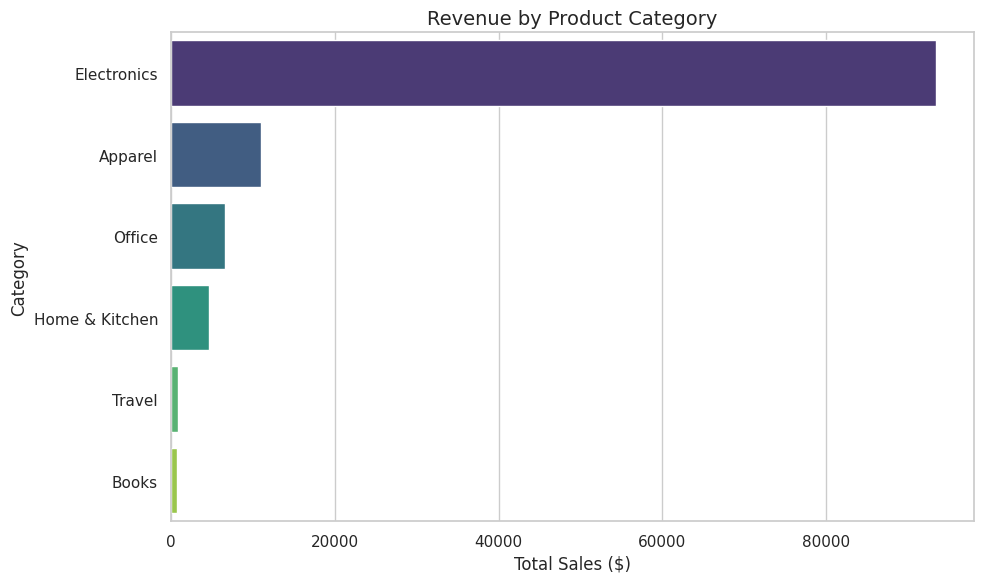

In [11]:
# 2. Revenue Distribution by Category
plt.figure(figsize=(10, 6))
sns.barplot(data=category_summary, x='total_sales', y='category', palette='viridis')
plt.title('Revenue by Product Category', fontsize=14)
plt.xlabel('Total Sales ($)', fontsize=12)
plt.ylabel('Category', fontsize=12)
plt.tight_layout()
plt.show()

## Phase 4: Customer Segmentation & Demographics

Let's categorize our customers into age cohorts and analyze their buying behavior to understand who drives the most revenue.

In [12]:
# Bin customers into logical age categories
bins = [0, 25, 45, 60, 100]
labels = ['18-25', '26-45', '46-60', '60+']
df_customers['age_group'] = pd.cut(df_customers['age'], bins=bins, labels=labels)

# Combine datasets to map demographics to their purchases
df_customer_orders = df_orders.merge(df_customers, on='customer_id', how='left')

# Aggregate spending metrics by cohort
age_group_summary = df_customer_orders.groupby('age_group', observed=False).agg(
    total_spend=('total_value', 'sum'),
    order_count=('order_id', 'count')
).reset_index()

print("=== Spending by Customer Age Group ===")
display(age_group_summary)

=== Spending by Customer Age Group ===


,age_group,total_spend,order_count
0,18-25,23419.02,71
1,26-45,50776.82,228
2,46-60,24933.49,115
3,60+,18103.85,86


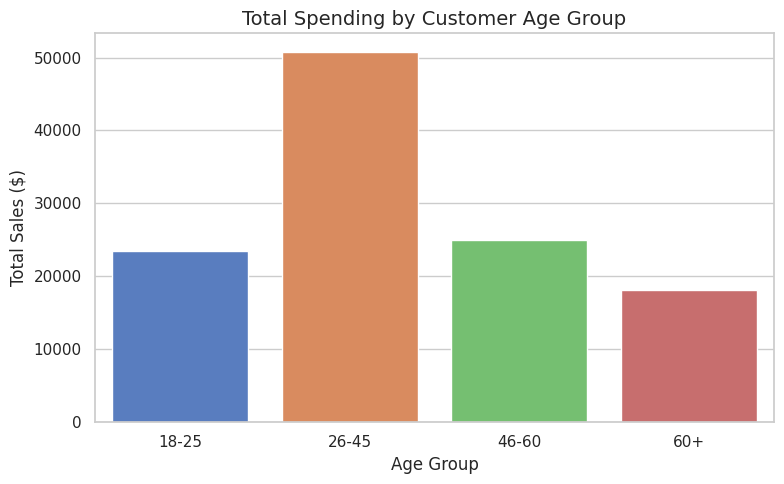

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))
sns.barplot(data=age_group_summary, x='age_group', y='total_spend', hue='age_group', palette='muted', legend=False)
plt.title('Total Spending by Customer Age Group', fontsize=14)
plt.xlabel('Age Group', fontsize=12)
plt.ylabel('Total Sales ($)', fontsize=12)
plt.tight_layout()
plt.show()

## Phase 4: Customer Segmentation & Demographics

Let's categorize our customers into age cohorts and analyze their buying behavior to understand who drives the most revenue.

In [14]:
# Bin customers into logical age categories
bins = [0, 25, 45, 60, 100]
labels = ['18-25', '26-45', '46-60', '60+']
df_customers['age_group'] = pd.cut(df_customers['age'], bins=bins, labels=labels)

# Combine datasets to map demographics to their purchases
df_customer_orders = df_orders.merge(df_customers, on='customer_id', how='left')

# Aggregate spending metrics by cohort
age_group_summary = df_customer_orders.groupby('age_group', observed=False).agg(
    total_spend=('total_value', 'sum'),
    order_count=('order_id', 'count')
).reset_index()

print("=== Spending by Customer Age Group ===")
display(age_group_summary)

=== Spending by Customer Age Group ===


,age_group,total_spend,order_count
0,18-25,23419.02,71
1,26-45,50776.82,228
2,46-60,24933.49,115
3,60+,18103.85,86


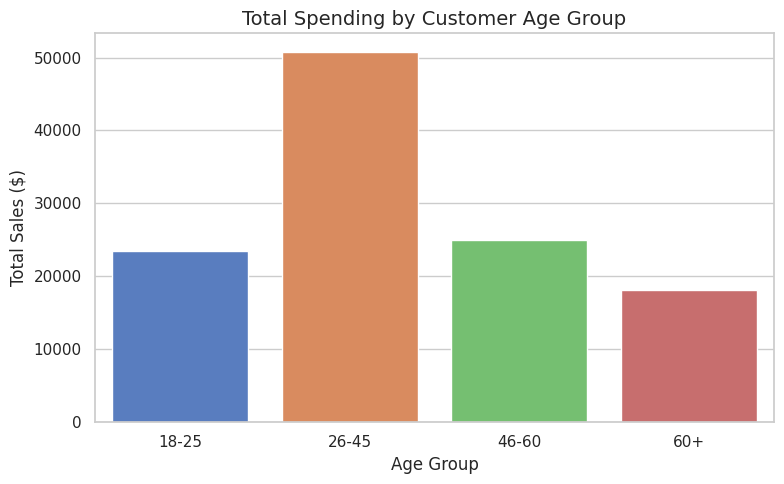

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))
sns.barplot(data=age_group_summary, x='age_group', y='total_spend', hue='age_group', palette='muted', legend=False)
plt.title('Total Spending by Customer Age Group', fontsize=14)
plt.xlabel('Age Group', fontsize=12)
plt.ylabel('Total Sales ($)', fontsize=12)
plt.tight_layout()
plt.show()

## Phase 4: Customer Segmentation & Demographics

Let's analyze how spending trends distribute across different customer age cohorts.

In [16]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Bin customers into logical age categories
bins = [0, 25, 45, 60, 100]
labels = ['18-25', '26-45', '46-60', '60+']
df_customers['age_group'] = pd.cut(df_customers['age'], bins=bins, labels=labels)

# Combine datasets to map demographics to their purchases
df_customer_orders = df_orders.merge(df_customers, on='customer_id', how='left')

# Aggregate spending metrics by cohort
age_group_summary = df_customer_orders.groupby('age_group', observed=False).agg(
    total_spend=('total_value', 'sum'),
    order_count=('order_id', 'count')
).reset_index()

print("=== Spending by Customer Age Group ===")
display(age_group_summary)

=== Spending by Customer Age Group ===


,age_group,total_spend,order_count
0,18-25,23419.02,71
1,26-45,50776.82,228
2,46-60,24933.49,115
3,60+,18103.85,86


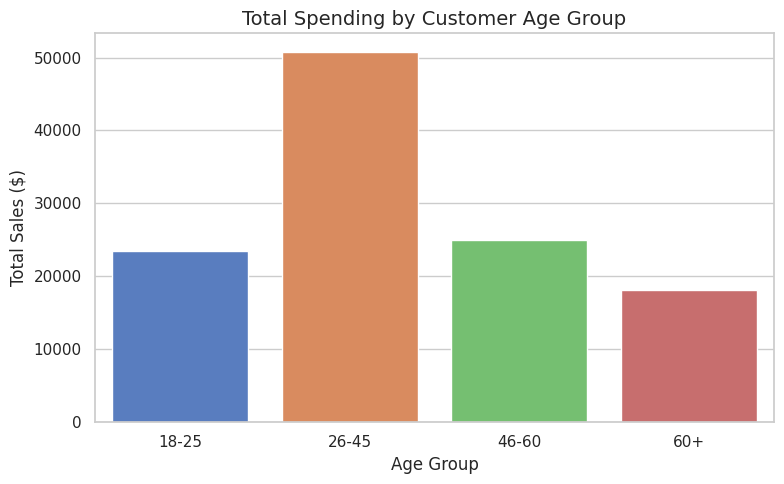

In [17]:
plt.figure(figsize=(8, 5))
sns.barplot(data=age_group_summary, x='age_group', y='total_spend', hue='age_group', palette='muted', legend=False)
plt.title('Total Spending by Customer Age Group', fontsize=14)
plt.xlabel('Age Group', fontsize=12)
plt.ylabel('Total Sales ($)', fontsize=12)
plt.tight_layout()
plt.show()

## Phase 4: Customer Segmentation & Demographics

Let's analyze how spending trends distribute across different customer age cohorts.

In [18]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Bin customers into logical age categories
bins = [0, 25, 45, 60, 100]
labels = ['18-25', '26-45', '46-60', '60+']
df_customers['age_group'] = pd.cut(df_customers['age'], bins=bins, labels=labels)

# Combine datasets to map demographics to their purchases
df_customer_orders = df_orders.merge(df_customers, on='customer_id', how='left')

# Aggregate spending metrics by cohort
age_group_summary = df_customer_orders.groupby('age_group', observed=False).agg(
    total_spend=('total_value', 'sum'),
    order_count=('order_id', 'count')
).reset_index()

print("=== Spending by Customer Age Group ===")
display(age_group_summary)

=== Spending by Customer Age Group ===


,age_group,total_spend,order_count
0,18-25,23419.02,71
1,26-45,50776.82,228
2,46-60,24933.49,115
3,60+,18103.85,86


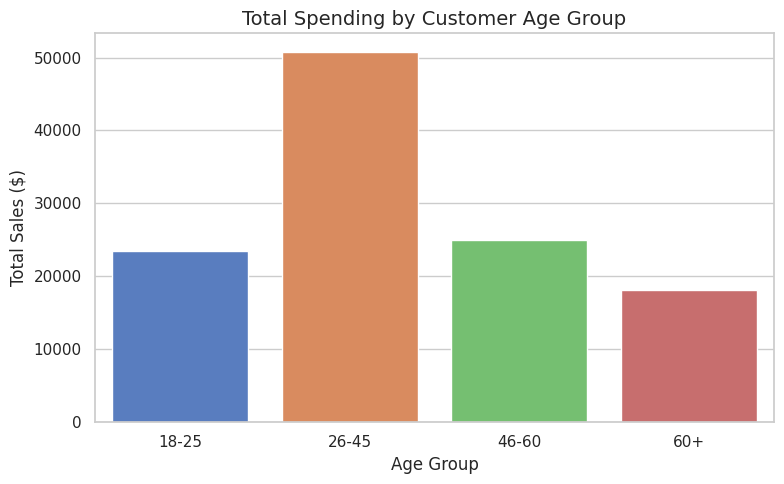

In [19]:
plt.figure(figsize=(8, 5))
sns.barplot(data=age_group_summary, x='age_group', y='total_spend', hue='age_group', palette='muted', legend=False)
plt.title('Total Spending by Customer Age Group', fontsize=14)
plt.xlabel('Age Group', fontsize=12)
plt.ylabel('Total Sales ($)', fontsize=12)
plt.tight_layout()
plt.show()

## Phase 4: Customer Segmentation & Demographics

Let's analyze how spending trends distribute across different customer age cohorts.

In [20]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Bin customers into logical age categories
bins = [0, 25, 45, 60, 100]
labels = ['18-25', '26-45', '46-60', '60+']
df_customers['age_group'] = pd.cut(df_customers['age'], bins=bins, labels=labels)

# Combine datasets to map demographics to their purchases
df_customer_orders = df_orders.merge(df_customers, on='customer_id', how='left')

# Aggregate spending metrics by cohort
age_group_summary = df_customer_orders.groupby('age_group', observed=False).agg(
    total_spend=('total_value', 'sum'),
    order_count=('order_id', 'count')
).reset_index()

print("=== Spending by Customer Age Group ===")
display(age_group_summary)

=== Spending by Customer Age Group ===


,age_group,total_spend,order_count
0,18-25,23419.02,71
1,26-45,50776.82,228
2,46-60,24933.49,115
3,60+,18103.85,86


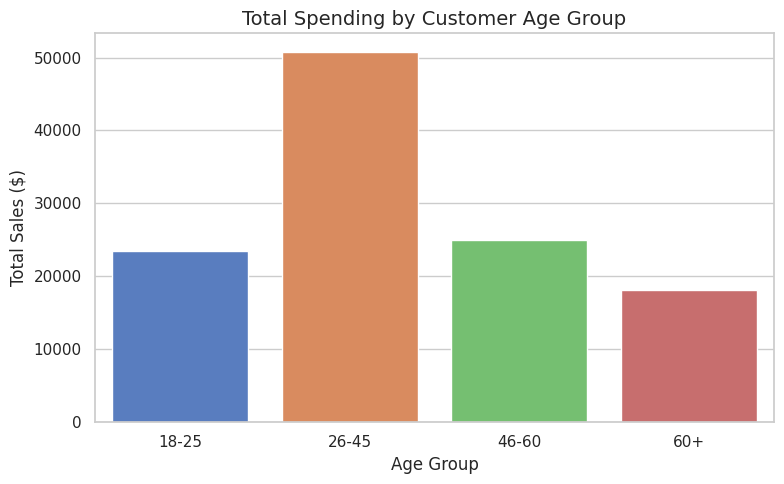

In [21]:
plt.figure(figsize=(8, 5))
sns.barplot(data=age_group_summary, x='age_group', y='total_spend', hue='age_group', palette='muted', legend=False)
plt.title('Total Spending by Customer Age Group', fontsize=14)
plt.xlabel('Age Group', fontsize=12)
plt.ylabel('Total Sales ($)', fontsize=12)
plt.tight_layout()
plt.show()

## Phase 4: Customer Segmentation & Demographics

Now, let's explore customer age demographics and see if we can group them into segments (e.g., Young Adults, Middle Aged, Seniors) to see which age groups spend the most.

In [22]:
# Categorize customers into age groups
bins = [0, 25, 45, 60, 100]
labels = ['18-25', '26-45', '46-60', '60+']
df_customers['age_group'] = pd.cut(df_customers['age'], bins=bins, labels=labels)

# Merge orders with customers to get demographic information
df_customer_orders = df_orders.merge(df_customers, on='customer_id', how='left')

# Analyze revenue by age group
age_group_summary = df_customer_orders.groupby('age_group', observed=False).agg(
    total_spend=('total_value', 'sum'),
    order_count=('order_id', 'count')
).reset_index()

print("=== Spending by Age Group ===")
display(age_group_summary)

=== Spending by Age Group ===


,age_group,total_spend,order_count
0,18-25,23419.02,71
1,26-45,50776.82,228
2,46-60,24933.49,115
3,60+,18103.85,86


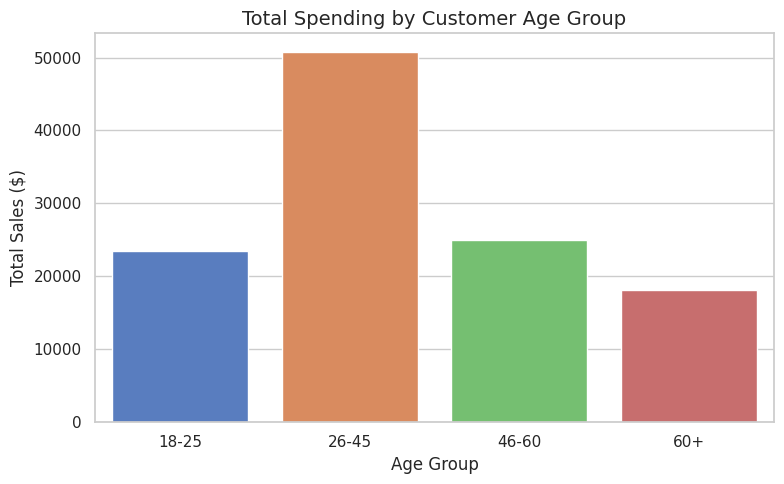

In [23]:
# Let's plot the spending distribution by Age Group with fixed seaborn options
plt.figure(figsize=(8, 5))
sns.barplot(data=age_group_summary, x='age_group', y='total_spend', hue='age_group', palette='muted', legend=False)
plt.title('Total Spending by Customer Age Group', fontsize=14)
plt.xlabel('Age Group', fontsize=12)
plt.ylabel('Total Sales ($)', fontsize=12)
plt.tight_layout()
plt.show()

## Phase 5: High-Value Customer (VIP) Analysis

Let's isolate our top 10 customers by total spend to see who our most valuable customers are and how frequently they buy from us.

In [24]:
# Calculate total spend and order frequency for each customer
customer_value_df = df_orders.groupby('customer_id').agg(
    total_spend=('total_value', 'sum'),
    total_orders=('order_id', 'nunique')
).reset_index()

# Sort to find our top 10 customers
top_customers = customer_value_df.sort_values(by='total_spend', ascending=False).head(10)

print("=== Top 10 Customers by Total Spend ===")
display(top_customers)

=== Top 10 Customers by Total Spend ===


,customer_id,total_spend,total_orders
22,C_1022,5094.86,8
60,C_1060,4179.92,6
38,C_1038,4109.88,8
24,C_1024,4039.89,6
84,C_1084,3774.91,7
57,C_1057,3774.80,13
19,C_1019,3239.94,3
18,C_1018,3189.86,8
6,C_1006,3054.95,3
23,C_1023,2929.89,8


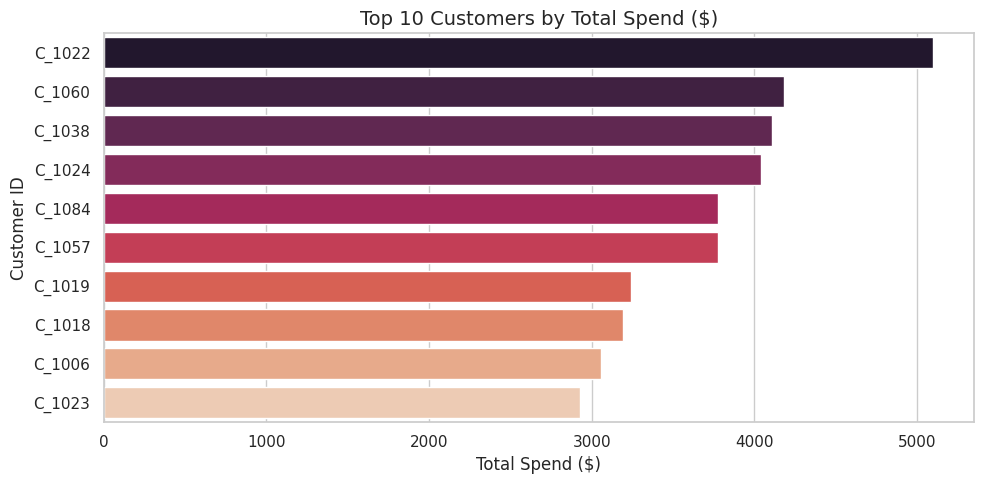

In [25]:
import matplotlib.pyplot as plt
import seaborn as sns

# Visualize our VIP customers
plt.figure(figsize=(10, 5))
sns.barplot(data=top_customers, x='total_spend', y='customer_id', hue='customer_id', palette='rocket', legend=False)
plt.title('Top 10 Customers by Total Spend ($)', fontsize=14)
plt.xlabel('Total Spend ($)', fontsize=12)
plt.ylabel('Customer ID', fontsize=12)
plt.tight_layout()
plt.show()

## Phase 5: High-Value Customer (VIP) Analysis

Let's isolate our top 10 customers by total spend to see who our most valuable customers are and how frequently they buy from us.

In [26]:
# Calculate total spend and order frequency for each customer
customer_value_df = df_orders.groupby('customer_id').agg(
    total_spend=('total_value', 'sum'),
    total_orders=('order_id', 'nunique')
).reset_index()

# Sort to find our top 10 customers
top_customers = customer_value_df.sort_values(by='total_spend', ascending=False).head(10)

print("=== Top 10 Customers by Total Spend ===")
display(top_customers)

=== Top 10 Customers by Total Spend ===


,customer_id,total_spend,total_orders
22,C_1022,5094.86,8
60,C_1060,4179.92,6
38,C_1038,4109.88,8
24,C_1024,4039.89,6
84,C_1084,3774.91,7
57,C_1057,3774.80,13
19,C_1019,3239.94,3
18,C_1018,3189.86,8
6,C_1006,3054.95,3
23,C_1023,2929.89,8


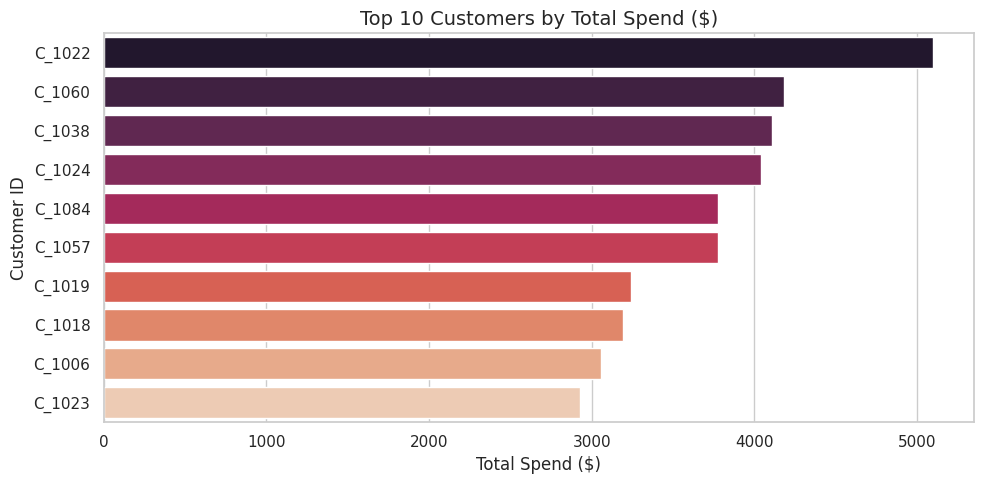

In [27]:
import matplotlib.pyplot as plt
import seaborn as sns

# Visualize our VIP customers
plt.figure(figsize=(10, 5))
sns.barplot(data=top_customers, x='total_spend', y='customer_id', hue='customer_id', palette='rocket', legend=False)
plt.title('Top 10 Customers by Total Spend ($)', fontsize=14)
plt.xlabel('Total Spend ($)', fontsize=12)
plt.ylabel('Customer ID', fontsize=12)
plt.tight_layout()
plt.show()

## Phase 5: High-Value Customer (VIP) Analysis

Let's isolate our top 10 customers by total spend to see who our most valuable customers are and how frequently they buy from us.

In [28]:
# Calculate total spend and order frequency for each customer
customer_value_df = df_orders.groupby('customer_id').agg(
    total_spend=('total_value', 'sum'),
    total_orders=('order_id', 'nunique')
).reset_index()

# Sort to find our top 10 customers
top_customers = customer_value_df.sort_values(by='total_spend', ascending=False).head(10)

print("=== Top 10 Customers by Total Spend ===")
display(top_customers)

=== Top 10 Customers by Total Spend ===


,customer_id,total_spend,total_orders
22,C_1022,5094.86,8
60,C_1060,4179.92,6
38,C_1038,4109.88,8
24,C_1024,4039.89,6
84,C_1084,3774.91,7
57,C_1057,3774.80,13
19,C_1019,3239.94,3
18,C_1018,3189.86,8
6,C_1006,3054.95,3
23,C_1023,2929.89,8


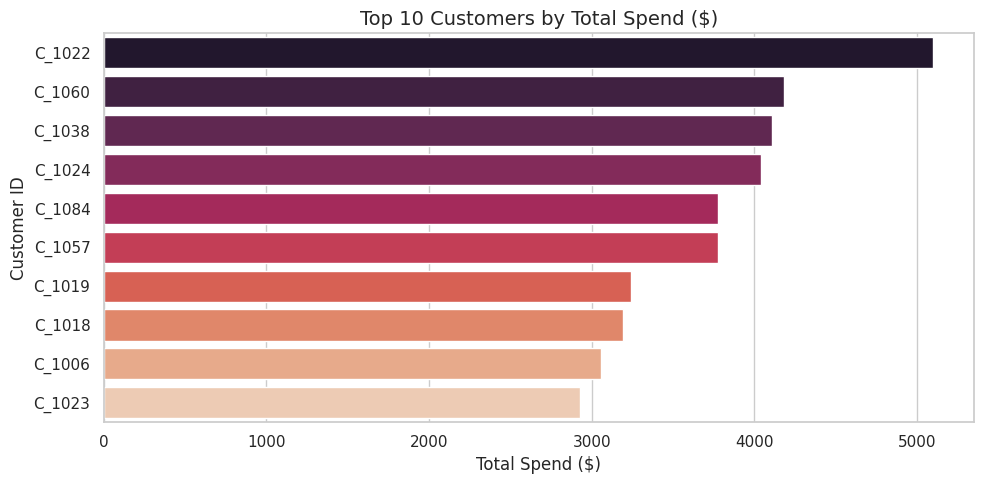

In [29]:
import matplotlib.pyplot as plt
import seaborn as sns

# Visualize our VIP customers with deprecation warning resolved
plt.figure(figsize=(10, 5))
sns.barplot(data=top_customers, x='total_spend', y='customer_id', hue='customer_id', palette='rocket', legend=False)
plt.title('Top 10 Customers by Total Spend ($)', fontsize=14)
plt.xlabel('Total Spend ($)', fontsize=12)
plt.ylabel('Customer ID', fontsize=12)
plt.tight_layout()
plt.show()

## Phase 5: High-Value Customer (VIP) Analysis

Let's isolate our top 10 customers by total spend to see who our most valuable customers are and how frequently they buy from us.

In [30]:
# Calculate total spend and order frequency for each customer
customer_value_df = df_orders.groupby('customer_id').agg(
    total_spend=('total_value', 'sum'),
    total_orders=('order_id', 'nunique')
).reset_index()

# Sort to find our top 10 customers
top_customers = customer_value_df.sort_values(by='total_spend', ascending=False).head(10)

print("=== Top 10 Customers by Total Spend ===")
display(top_customers)

=== Top 10 Customers by Total Spend ===


,customer_id,total_spend,total_orders
22,C_1022,5094.86,8
60,C_1060,4179.92,6
38,C_1038,4109.88,8
24,C_1024,4039.89,6
84,C_1084,3774.91,7
57,C_1057,3774.80,13
19,C_1019,3239.94,3
18,C_1018,3189.86,8
6,C_1006,3054.95,3
23,C_1023,2929.89,8


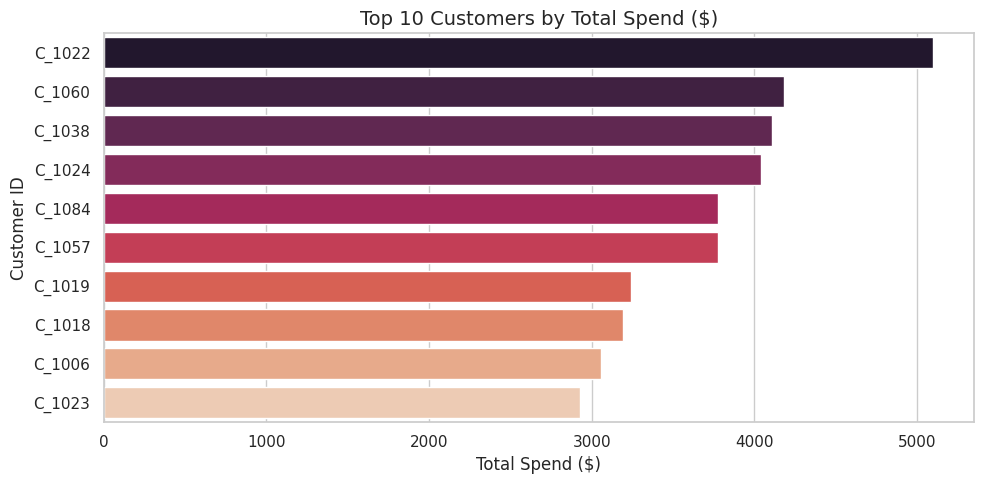

In [31]:
import matplotlib.pyplot as plt
import seaborn as sns

# Visualize our VIP customers
plt.figure(figsize=(10, 5))
sns.barplot(data=top_customers, x='total_spend', y='customer_id', hue='customer_id', palette='rocket', legend=False)
plt.title('Top 10 Customers by Total Spend ($)', fontsize=14)
plt.xlabel('Total Spend ($)', fontsize=12)
plt.ylabel('Customer ID', fontsize=12)
plt.tight_layout()
plt.show()

## Phase 5: High-Value Customer Analysis

Let's isolate our top 10 customers by total spend to see who our most valuable customers are and how frequently they buy from us.

In [32]:
# Calculate total spend and order frequency for each customer
customer_value_df = df_orders.groupby('customer_id').agg(
    total_spend=('total_value', 'sum'),
    total_orders=('order_id', 'nunique')
).reset_index()

# Sort to find our top 10 customers
top_customers = customer_value_df.sort_values(by='total_spend', ascending=False).head(10)

print("=== Top 10 Customers by Total Spend ===")
display(top_customers)

=== Top 10 Customers by Total Spend ===


,customer_id,total_spend,total_orders
22,C_1022,5094.86,8
60,C_1060,4179.92,6
38,C_1038,4109.88,8
24,C_1024,4039.89,6
84,C_1084,3774.91,7
57,C_1057,3774.80,13
19,C_1019,3239.94,3
18,C_1018,3189.86,8
6,C_1006,3054.95,3
23,C_1023,2929.89,8


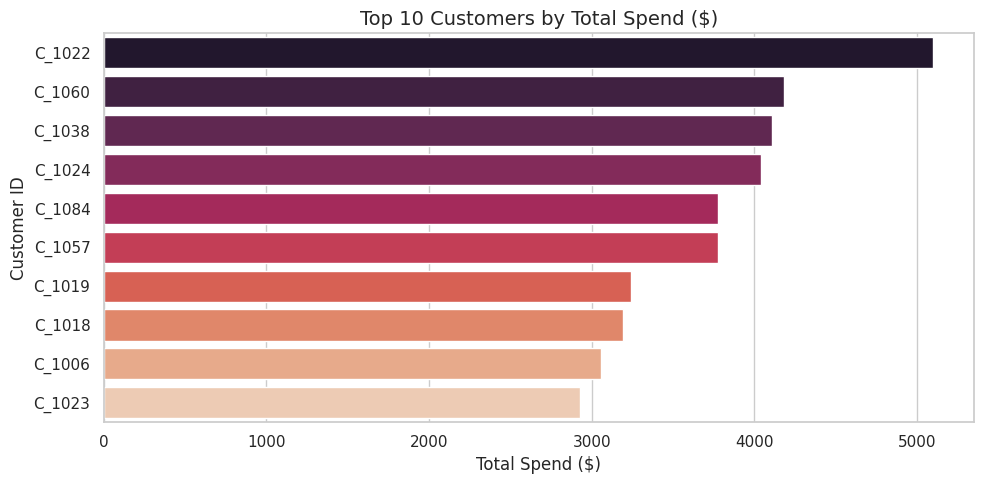

In [33]:
import matplotlib.pyplot as plt
import seaborn as sns

# Visualize our VIP customers
plt.figure(figsize=(10, 5))
sns.barplot(data=top_customers, x='total_spend', y='customer_id', hue='customer_id', palette='rocket', legend=False)
plt.title('Top 10 Customers by Total Spend ($)', fontsize=14)
plt.xlabel('Total Spend ($)', fontsize=12)
plt.ylabel('Customer ID', fontsize=12)
plt.tight_layout()
plt.show()

## Phase 6: Predict Customer Churn using Classification

In this section, we will build a machine learning pipeline to predict customer churn.
1. **Define Churn**: Since this is non-subscription e-commerce, we will label a customer as "churned" (1) if they have not placed an order in the last 60 days of our 180-day operational period, and "active" (0) otherwise.
2. **Feature Engineering**: We will construct features for each customer, such as age, signup tenure (days from signup to the end of the analysis period), total purchase count, and total spend.
3. **Model Development**: We will train a Random Forest Classifier and evaluate its performance.

In [35]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import pandas as pd
import numpy as np

# 1. Define the end date of our observation period based on the last order in the dataset
end_date = df_orders['order_date'].max()

# Calculate recency (days since last order) for each customer
recency_df = df_orders.groupby('customer_id').agg(last_order_date=('order_date', 'max')).reset_index()
recency_df['recency_days'] = (end_date - recency_df['last_order_date']).dt.days

# Define Churn: 1 if recency > 60 days, else 0
recency_df['churn'] = (recency_df['recency_days'] > 60).astype(int)

# 2. Extract tenure (days since signup up to the end of our dataset)
df_customers['tenure_days'] = (end_date - df_customers['signup_date']).dt.days

# Create Feature Table
features_df = df_customers[['customer_id', 'age', 'tenure_days']].merge(
    customer_value_df, on='customer_id', how='left'
).merge(
    recency_df[['customer_id', 'churn']], on='customer_id', how='left'
)

# Handle customers who never placed an order (if any)
features_df['total_spend'] = features_df['total_spend'].fillna(0)
features_df['total_orders'] = features_df['total_orders'].fillna(0)
features_df['churn'] = features_df['churn'].fillna(1) # Never ordered = Churned

# Define Features (X) and Target (y)
X = features_df[['age', 'tenure_days', 'total_spend', 'total_orders']]
y = features_df['churn']

# 3. Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Initialize and train Model
clf = RandomForestClassifier(random_state=42, n_estimators=100)
clf.fit(X_train, y_train)

# Predict
y_pred = clf.predict(X_test)

# Evaluate
print("=== Classification Performance Report ===")
print(classification_report(y_test, y_pred))

# Display Feature Importance
feature_importances = pd.Series(clf.feature_importances_, index=X.columns).sort_values(ascending=False)
print("\n=== Feature Importance ===")
print(feature_importances)

=== Classification Performance Report ===
              precision    recall  f1-score   support

         0.0       0.95      1.00      0.97        18
         1.0       1.00      0.50      0.67         2

    accuracy                           0.95        20
   macro avg       0.97      0.75      0.82        20
weighted avg       0.95      0.95      0.94        20


=== Feature Importance ===
total_spend     0.292304
total_orders    0.257181
tenure_days     0.232923
age             0.217593
dtype: float64


### Visualizing Churn Predictors & Performance with Heatmaps

To better understand our classification performance and the relationship between our engineered features, we will plot:
1. The **Confusion Matrix Heatmap**.
2. The **Correlation Heatmap** of customer features.

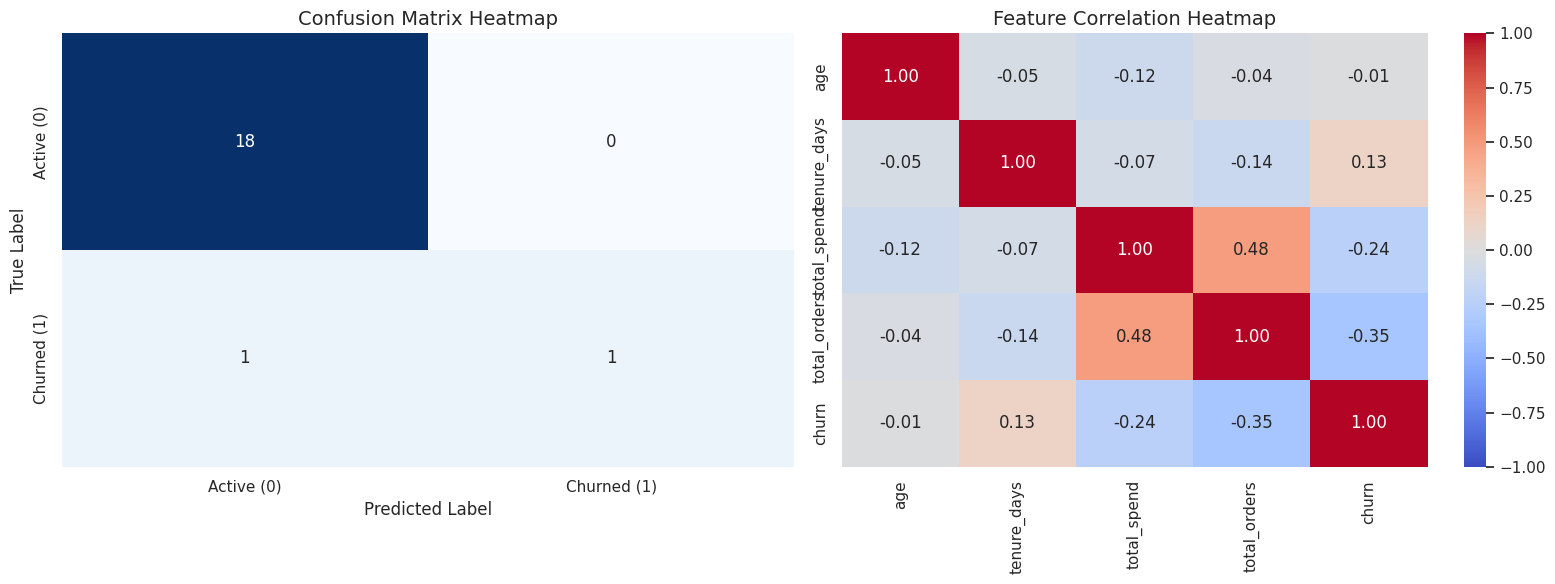

In [36]:
import seaborn as sns
import matplotlib.pyplot as plt

# Calculate confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Setup the plotting environment with two subplots side-by-side
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Confusion Matrix Heatmap
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Active (0)', 'Churned (1)'],
    yticklabels=['Active (0)', 'Churned (1)'],
    ax=axes[0],
    cbar=False
)
axes[0].set_title('Confusion Matrix Heatmap', fontsize=14)
axes[0].set_xlabel('Predicted Label', fontsize=12)
axes[0].set_ylabel('True Label', fontsize=12)

# 2. Correlation Matrix Heatmap
correlation_matrix = features_df[['age', 'tenure_days', 'total_spend', 'total_orders', 'churn']].corr()
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    vmin=-1,
    vmax=1,
    ax=axes[1]
)
axes[1].set_title('Feature Correlation Heatmap', fontsize=14)

plt.tight_layout()
plt.show()